Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


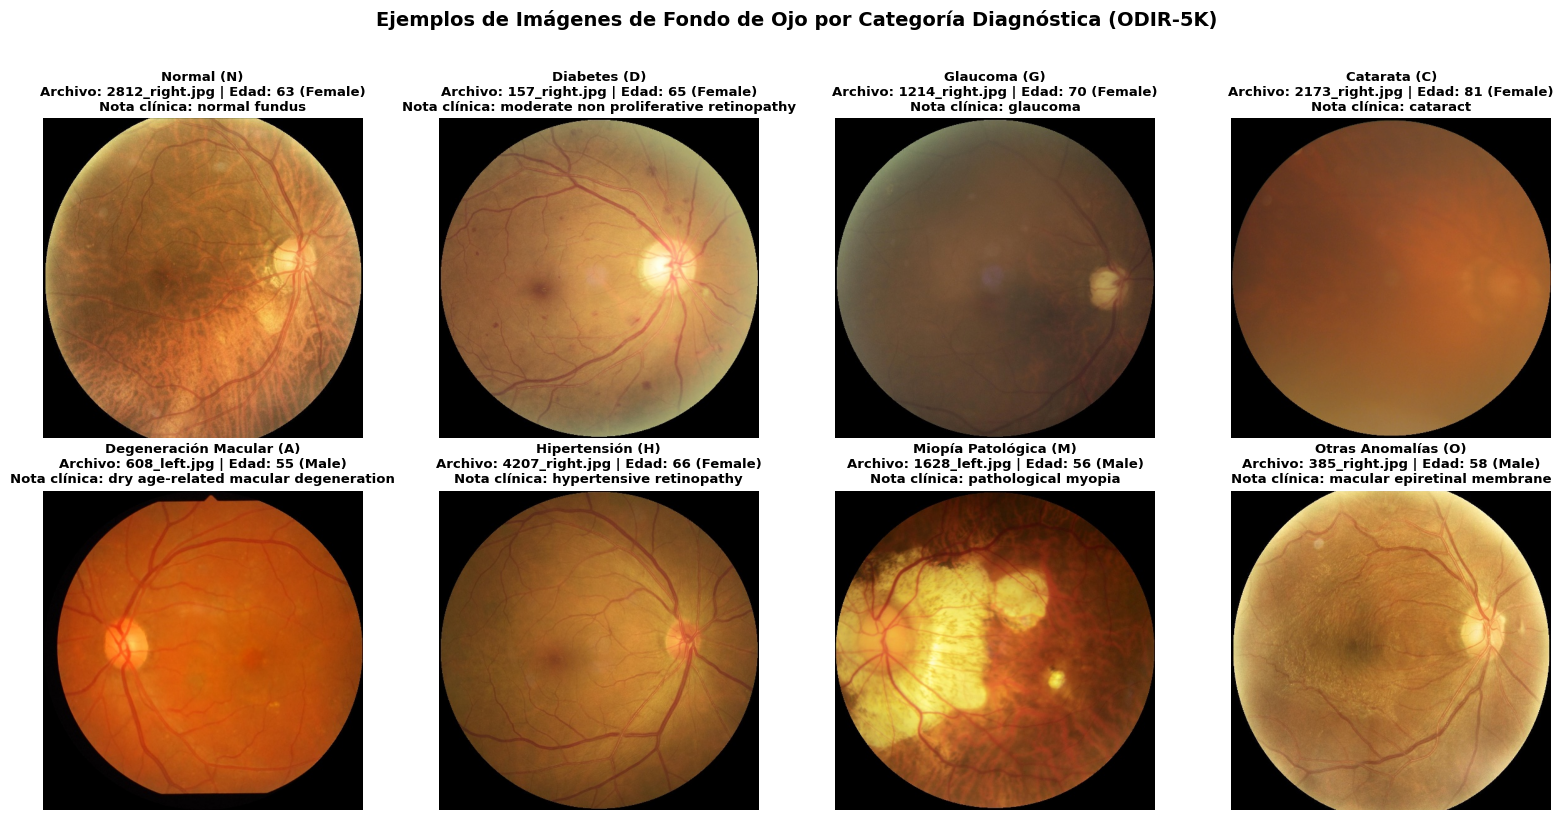

In [ ]:
# ==============================================================================
# CUADERNO 06: VISUALIZACIÓN DE MUESTRAS CLÍNICAS POR CADA CLASE (ODIR-5K)
# ==============================================================================
from google.colab import drive
import os
import ast
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 1. Montar Google Drive y definir rutas
drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/BaseDatos'
CSV_PATH = os.path.join(BASE_DIR, 'full_df.csv')
PREPROC_DIR = os.path.join(BASE_DIR, 'preprocessed_images')

assert os.path.exists(CSV_PATH), f"No se encontró {CSV_PATH}"
assert os.path.exists(PREPROC_DIR), f"No se encontró {PREPROC_DIR}"

# 2. Cargar dataset y filtrar imágenes existentes
df = pd.read_csv(CSV_PATH)
archivos_existentes = set(os.listdir(PREPROC_DIR))
df = df[df['filename'].isin(archivos_existentes)].copy().reset_index(drop=True)

# Extraer código de clase individual por ojo
df['clase'] = df['labels'].apply(lambda x: ast.literal_eval(x)[0])

nombres_clases = {
    'N': 'Normal (N)',
    'D': 'Diabetes (D)',
    'G': 'Glaucoma (G)',
    'C': 'Catarata (C)',
    'A': 'Degeneración Macular (A)',
    'H': 'Hipertensión (H)',
    'M': 'Miopía Patológica (M)',
    'O': 'Otras Anomalías (O)'
}

clases_ordenadas = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']

# 3. Extraer el diagnóstico textual específico del ojo mostrado (izquierdo o derecho)
def obtener_diagnostico_ojo(row):
    if '_left.jpg' in row['filename']:
        return row['Left-Diagnostic Keywords']
    return row['Right-Diagnostic Keywords']

df['diagnostico_texto'] = df.apply(obtener_diagnostico_ojo, axis=1)

# 4. Graficar una cuadrícula 2x4 con un ejemplo representativo de cada clase
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, codigo in enumerate(clases_ordenadas):
    # Seleccionar 1 muestra aleatoria de esa clase (random_state=42 para reproducibilidad)
    muestra = df[df['clase'] == codigo].sample(n=1, random_state=42).iloc[0]
    img_path = os.path.join(PREPROC_DIR, muestra['filename'])
    img = Image.open(img_path).convert('RGB')

    axes[idx].imshow(img)
    axes[idx].set_title(
        f"{nombres_clases[codigo]}\n"
        f"Archivo: {muestra['filename']} | Edad: {muestra['Patient Age']} ({muestra['Patient Sex']})\n"
        f"Nota clínica: {muestra['diagnostico_texto'][:38]}",
        fontsize=9.5,
        fontweight='bold'
    )
    axes[idx].axis('off')

plt.suptitle("Ejemplos de Imágenes de Fondo de Ojo por Categoría Diagnóstica (ODIR-5K)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()